In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def flat_without_diagonal(matrix):

    matrix = matrix.copy()
    n = matrix.shape[0]
    upper = matrix[np.triu_indices(n, k =  1)]
    lower = matrix[np.tril_indices(n, k = -1)]
    
    return np.concatenate([upper, lower])

#### Prediction $R^2$

In [3]:
res_ridge = pd.read_csv('../results/fig02/validation_res_HCP_MMP(distance_ridge).csv'); res_ridge['FILE_ID'] = res_ridge['FILE_ID'].astype(str)
summary_ridge = res_ridge.drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['R2_5fold(raw)']

res_lasso = pd.read_csv('../results/fig02/validation_res_HCP_MMP(distance_lasso).csv'); res_lasso['FILE_ID'] = res_lasso['FILE_ID'].astype(str)
summary_lasso = res_lasso.drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['R2_5fold(raw)']

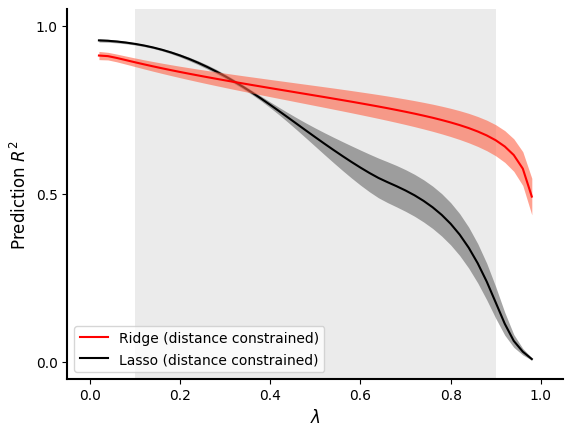

In [4]:
mean = summary_ridge['mean'].values; std = summary_ridge['std'].values
plt.plot(summary_ridge.index, mean, c = 'r', zorder = 5, label = 'Ridge (distance constrained)')
plt.fill_between(summary_ridge.index, mean - std, mean + std, color = 'tomato', lw = 0, alpha = 0.6, zorder = 4)

mean = summary_lasso['mean'].values; std = summary_lasso['std'].values
plt.plot(summary_lasso.index, mean, c = 'k', zorder = 3, label = 'Lasso (distance constrained)')
plt.fill_between(summary_lasso.index, mean - std, mean + std, color = 'dimgray', lw = 0, alpha = 0.6, zorder = 2)

plt.fill_betweenx([-2, 2], [0.1, 0.1], [0.9, 0.9], color = 'silver', lw = 0, alpha = 0.3, zorder = 1)

ax = plt.gca()
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)

plt.xlabel(r'$\lambda$', fontsize = 12); plt.xlim(-0.05, 1.05); plt.xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], fontsize = 10)
plt.ylabel(r'Prediction $R^2$', fontsize = 12); plt.ylim(-0.05, 1.05); plt.yticks([0.0, 0.5, 1.0], fontsize = 10)
plt.legend(fontsize = 10, loc = 'lower left')

plt.show()

#### W - SC corr

In [5]:
lambdas = np.linspace(0.02, 0.98, 49)

mean_Ws_ridge = np.load('../results/fig02/mean_W_HCP_MMP(distance_ridge).npz')['arr_0']
mean_Ws_lasso = np.load('../results/fig02/mean_W_HCP_MMP(distance_lasso).npz')['arr_0']

sc = np.load('../results/fig02/mean_SC_HCP_MMP.npz')['arr_0']

res_ridge = np.array([np.corrcoef(flat_without_diagonal(mean_Ws_ridge[i]), flat_without_diagonal(sc))[0, 1] for i in range(mean_Ws_ridge.shape[0])])
res_lasso = np.array([np.corrcoef(flat_without_diagonal(mean_Ws_lasso[i]), flat_without_diagonal(sc))[0, 1] for i in range(mean_Ws_lasso.shape[0])])

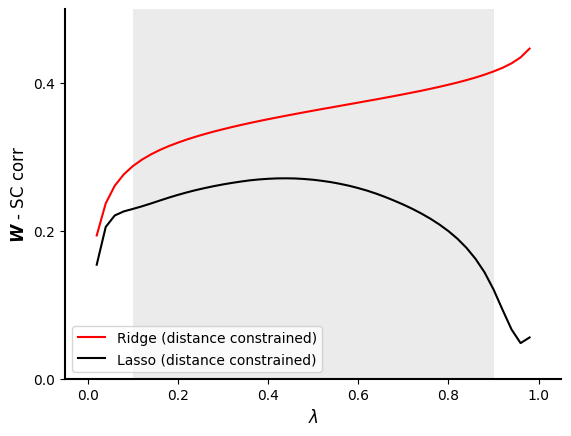

In [6]:
plt.plot(lambdas, res_ridge, c = 'r', zorder = 2, label = 'Ridge (distance constrained)')
plt.plot(lambdas, res_lasso, c = 'k', zorder = 2, label = 'Lasso (distance constrained)')

plt.fill_betweenx([-2, 2], [0.1, 0.1], [0.9, 0.9], color = 'silver', lw = 0, alpha = 0.3, zorder = 1)

ax = plt.gca()
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)

plt.xlabel(r'$\lambda$', fontsize = 12); plt.xlim(-0.05, 1.05); plt.xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], fontsize = 10)
plt.ylabel(r'$\boldsymbol{W}$ - SC corr', fontsize = 12); plt.ylim(0.0, 0.5); plt.yticks([0.0, 0.2, 0.4], fontsize = 10)
plt.legend(fontsize = 10, loc = 'lower left')

plt.show()

#### Model - empirical FC corr

In [7]:
res_ridge = pd.read_csv('../results/fig02/validation_res_HCP_MMP(distance_ridge).csv'); res_ridge['FILE_ID'] = res_ridge['FILE_ID'].astype(str)
summary_ridge = res_ridge.drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['FC_recon']

res_lasso = pd.read_csv('../results/fig02/validation_res_HCP_MMP(distance_lasso).csv'); res_lasso['FILE_ID'] = res_lasso['FILE_ID'].astype(str)
summary_lasso = res_lasso.drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['FC_recon']

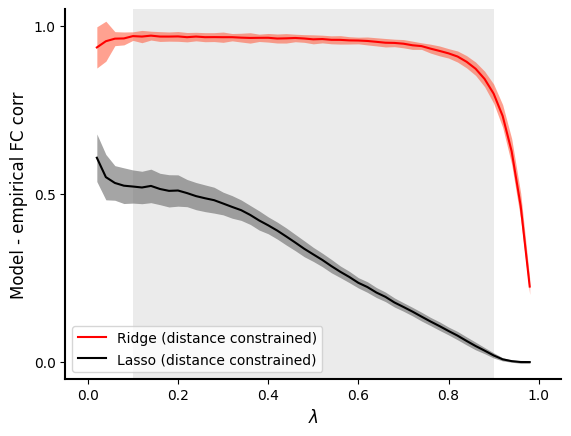

In [8]:
mean = summary_ridge['mean'].values; std = summary_ridge['std'].values
plt.plot(summary_ridge.index, mean, c = 'r', zorder = 5, label = 'Ridge (distance constrained)')
plt.fill_between(summary_ridge.index, mean - std, mean + std, color = 'tomato', lw = 0, alpha = 0.6, zorder = 4)

mean = summary_lasso['mean'].values; std = summary_lasso['std'].values
plt.plot(summary_lasso.index, mean, c = 'k', zorder = 3, label = 'Lasso (distance constrained)')
plt.fill_between(summary_lasso.index, mean - std, mean + std, color = 'dimgray', lw = 0, alpha = 0.6, zorder = 2)

plt.fill_betweenx([-2, 2], [0.1, 0.1], [0.9, 0.9], color = 'silver', lw = 0, alpha = 0.3, zorder = 1)

ax = plt.gca()
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)

plt.xlabel(r'$\lambda$', fontsize = 12); plt.xlim(-0.05, 1.05); plt.xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], fontsize = 10)
plt.ylabel(r'Model - empirical FC corr', fontsize = 12); plt.ylim(-0.05, 1.05); plt.yticks([0.0, 0.5, 1.0], fontsize = 10)
plt.legend(fontsize = 10, loc = 'lower left')

plt.show()

#### W - NPI-EC corr

In [9]:
indiv_EC = np.load('../results/fig02/indiv_NPI-EC_HCP_MMP.npz')['arr_0']
indiv_W  = np.load('../results/fig02/indiv_W_HCP_MMP(distance_ridge_0.70).npz')['arr_0']

e = 0; w = 0
for i in range(indiv_EC.shape[0]): 
    e = max(np.max(abs(flat_without_diagonal(indiv_EC[i]))), e)
    w = max(np.max(abs(flat_without_diagonal(indiv_W[i]))), w)
indiv_EC /= e; indiv_W /= w

labels = list(np.loadtxt('../results/fig02/mmplabels.txt', dtype = str))
source_label = 'R_V1'; source_idx = labels.index(source_label)
target_label = 'R_V2'; target_idx = labels.index(target_label)

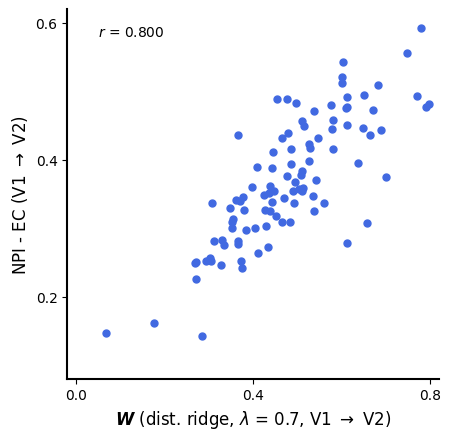

In [10]:
plt.figure(figsize = (4.8, 4.8))

plt.scatter(indiv_W[:, target_idx, source_idx], indiv_EC[:, target_idx, source_idx], color = 'royalblue', s = 25)

ax = plt.gca()
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)

plt.xlabel(r'$\boldsymbol{W}$ (dist. ridge, $\lambda$ = 0.7, V1 $\rightarrow$ V2)', fontsize = 12); plt.xlim(-0.02, 0.82); plt.xticks([0.0, 0.4, 0.8], fontsize = 10)
plt.ylabel(r'NPI - EC (V1 $\rightarrow$ V2)', fontsize = 12); plt.ylim(0.08, 0.62); plt.yticks([0.2, 0.4, 0.6], fontsize = 10)
plt.text(x = 0.05, y = 0.58, s = r'$r$ = {:.3f}'.format(np.corrcoef(indiv_W[:, target_idx, source_idx], indiv_EC[:, target_idx, source_idx])[0, 1]), fontsize = 10)

plt.show()

In [11]:
lambdas = np.linspace(0.02, 0.98, 49)
mean_Ws_ridge = np.load('../results/fig02/mean_W_HCP_MMP(distance_ridge).npz')['arr_0']
ec = np.load('../results/fig02/mean_NPI-EC_HCP_MMP.npz')['arr_0']
res_ridge = np.array([np.corrcoef(flat_without_diagonal(mean_Ws_ridge[i]), flat_without_diagonal(ec))[0, 1] for i in range(mean_Ws_ridge.shape[0])])
idx = np.where(res_ridge == np.max(res_ridge))[0][0]

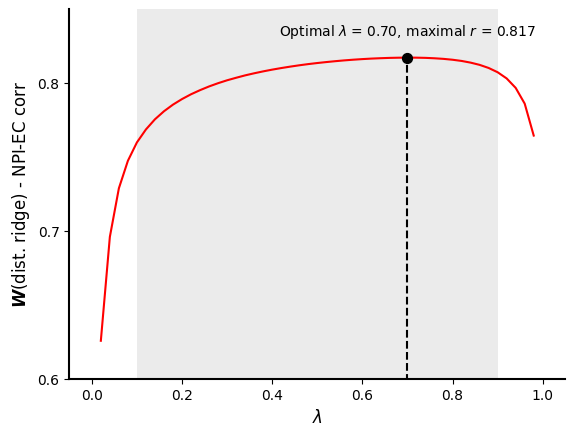

In [12]:
plt.plot(lambdas, res_ridge, c = 'r', zorder = 2)
plt.scatter(lambdas[idx], res_ridge[idx], c = 'k', s = 50, zorder = 3)
plt.vlines(lambdas[idx], ymin = 0.5, ymax = res_ridge[idx], color = 'k', linestyle = '--', zorder = 3)
plt.fill_betweenx([-2, 2], [0.1, 0.1], [0.9, 0.9], color = 'silver', lw = 0, alpha = 0.3, zorder = 1)

ax = plt.gca()
ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)

plt.xlabel(r'$\lambda$', fontsize = 12); plt.xlim(-0.05, 1.05); plt.xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], fontsize = 10)
plt.ylabel(r'$\boldsymbol{W}$(dist. ridge) - NPI-EC corr', fontsize = 12); plt.ylim(0.6, 0.85); plt.yticks([0.6, 0.7, 0.8], fontsize = 10)
plt.text(x = lambdas[idx], y = res_ridge[idx] + .015, s = r'Optimal $\lambda$ = {:.2f}, maximal $r$ = {:.3f}'.format(lambdas[idx], res_ridge[idx]), ha = 'center', fontsize = 10)

plt.show()